<table border=0 width="100%"><tr><td><p align="left"><img src="..\img\logo.png" align="left" width=300></p></td><td><font size=3><B>Quantitative trading Introduction (Haichao Zheng)</B></font></td></tr></table>

content 
- visualizing the distribution of comments data
- homework
- monthly investment strategy
- technical indicator
- homework in week 12

# Visualizing the distribution of comments data

## load the data set

In [1]:
# read the dataset
import pandas as pd
comments = pd.read_csv("300251.csv",encoding = "gbk",
                      names=["date","author","url","comment"])
comments.shape

(129856, 4)

In [5]:
comments.index

DatetimeIndex(['2019-03-25 16:13:22', '2019-03-26 15:47:21',
               '2019-03-26 16:18:41', '2019-03-26 17:04:14',
               '2019-03-26 17:30:25', '2019-03-26 17:59:37',
               '2019-03-26 19:23:21', '2019-03-26 16:46:55',
               '2019-03-26 22:01:47', '2019-03-26 22:35:22',
               ...
               '2011-08-04 18:09:07', '2011-08-04 19:35:52',
               '2011-08-04 16:37:36', '2011-08-04 17:58:16',
               '2011-08-04 17:44:20', '2011-08-04 20:15:14',
               '2011-07-29 08:04:39', '2011-07-25 12:29:19',
               '2011-07-30 19:57:17', '2011-08-04 18:02:48'],
              dtype='datetime64[ns]', name='date', length=129856, freq=None)

## when the people are active in terms of hour of day?

In [3]:
# set date as index, and change the index to datetime type
comments.set_index("date",inplace=True)
comments.index = pd.to_datetime(comments.index)

comments.tail()

,author,url,comment
date,,,
2011-08-04 20:15:14,None,"http://guba.eastmoney.com/news,300251,42050185...",\r\n 178\r\...
2011-07-29 08:04:39,None,"http://guba.eastmoney.com/news,300251,41736628...",\r\n 破发无悬念，...
2011-07-25 12:29:19,None,"http://guba.eastmoney.com/news,300251,41518803...",\r\n 破发从这个开...
2011-07-30 19:57:17,None,"http://guba.eastmoney.com/news,300251,41805573...",\r\n 无德，无道，...
2011-08-04 18:02:48,None,"http://guba.eastmoney.com/news,300251,42047194...",\r\n 买这个股的死...


<AxesSubplot:>

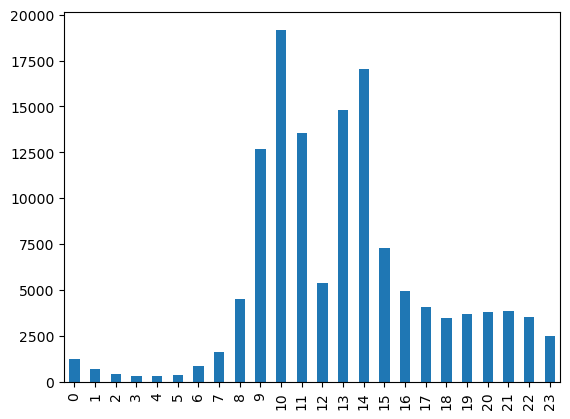

In [7]:
# use value_counts to explore the distribution of comments in each hour
# try groupby, or use value_counts() function

# comments.index.hour.unique()
# comments.index.hour.value_counts().sort_index().plot(kind="bar")

#comments.groupby(comments.index.hour).count()["url"].plot(kind="bar")

comments.index.hour.value_counts().sort_index().plot(kind="bar")

In [ ]:
# plot kind bar to show the value counts in each hour



## show me the dynamics of humans in each day of week

### day of week

"pandas.DatetimeIndex.dayofweek #. pandas.DatetimeIndex.dayofweek. #. The day of the week with Monday=0, Sunday=6. Return the day of the week. It is assumed the week starts on Monday, which is denoted by 0 and ends on Sunday which is denoted by 6.

In [22]:
import pandas as pd
import datetime

# 創建datetime對象
date = datetime.datetime(2023, 5, 5)

# 使用dayofweek方法獲取星期幾
day_of_week = date.weekday()
day_of_week

4

In [23]:
comments.head()

,author,url,comment
date,,,
2019-03-25 16:13:22,光线传媒资讯,"http://guba.eastmoney.com/news,300251,81164281...",\r\n 光线传媒:关...
2019-03-26 15:47:21,恭喜发财红利就来,"http://guba.eastmoney.com/news,300251,81192614...",\r\n 各位兄弟，再...
2019-03-26 16:18:41,老老老老老康,"http://guba.eastmoney.com/news,300251,81193282...",\r\n 继续加仓了，...
2019-03-26 17:04:14,说你点啥好呢,"http://guba.eastmoney.com/news,300251,81194240...",\r\n 跌破8块可以...
2019-03-26 17:30:25,资金解密,"http://guba.eastmoney.com/news,300251,81194742...",\r\n 光线传媒03...


In [24]:
# create a new columns: weekday and hour
comments["weekday"] = comments.index.weekday + 1
comments["hour"] = comments.index.hour

In [25]:
comments.head()

,author,url,comment,weekday,hour
date,,,,,
2019-03-25 16:13:22,光线传媒资讯,"http://guba.eastmoney.com/news,300251,81164281...",\r\n 光线传媒:关...,1,16
2019-03-26 15:47:21,恭喜发财红利就来,"http://guba.eastmoney.com/news,300251,81192614...",\r\n 各位兄弟，再...,2,15
2019-03-26 16:18:41,老老老老老康,"http://guba.eastmoney.com/news,300251,81193282...",\r\n 继续加仓了，...,2,16
2019-03-26 17:04:14,说你点啥好呢,"http://guba.eastmoney.com/news,300251,81194240...",\r\n 跌破8块可以...,2,17
2019-03-26 17:30:25,资金解密,"http://guba.eastmoney.com/news,300251,81194742...",\r\n 光线传媒03...,2,17


### groupby with multiple columns

In [9]:
# group the comments by multiple columns - comments.index.day_of_week+1, comments.index.hour
comments_by_time = comments.groupby([comments.index.weekday,comments.index.hour]).count()["url"]

In [14]:
comments["weekday"] = comments.index.weekday + 1
comments["hour"] = comments.index.hour
by_time = comments.groupby([comments.weekday,comments.hour]).count()
by_time = by_time["url"]

In [12]:
by_time = comments.groupby([comments.index.weekday,comments.index.hour]).count()
by_time = by_time["url"]
by_time

date  date
0     0       143
      1        82
      2        41
      3        28
      4        27
             ... 
6     19      324
      20      373
      21      418
      22      430
      23      295
Name: url, Length: 168, dtype: int64

In [35]:
# MultiIndex
by_time.index

MultiIndex([(1,  0),
            (1,  1),
            (1,  2),
            (1,  3),
            (1,  4),
            (1,  5),
            (1,  6),
            (1,  7),
            (1,  8),
            (1,  9),
            ...
            (7, 14),
            (7, 15),
            (7, 16),
            (7, 17),
            (7, 18),
            (7, 19),
            (7, 20),
            (7, 21),
            (7, 22),
            (7, 23)],
           names=['weekday', 'hour'], length=168)

In [38]:
# slice the dat
by_time.loc[2]

hour
0      188
1      101
2       60
3       42
4       45
5       89
6      150
7      282
8      793
9     2183
10    3566
11    2479
12     938
13    3061
14    3267
15    1238
16     799
17     669
18     506
19     568
20     592
21     608
22     559
23     434
Name: url, dtype: int64

In [39]:
# what do you get with df.loc[:,:"z"]
import pandas as pd
import numpy as np

# create a sample dataframe with multi-level indexes
arrays = [np.array(['bar', 'bar', 'baz', 'baz', 'foo', 'foo', 'qux', 'qux']),
          np.array(['one', 'two', 'one', 'two', 'one', 'two', 'one', 'two']),
          np.array(['x', 'y', 'x', 'y', 'x', 'y', 'x', 'y'])]
tuples = list(zip(*arrays))
index = pd.MultiIndex.from_tuples(tuples, names=['A', 'B', 'C'])
df = pd.DataFrame(np.random.randn(8, 3), index=index, columns=['X', 'Y', 'Z'])
df

X         Y         Z
A   B   C                              
bar one x -1.001655 -1.562164 -1.811790
    two y -0.367428 -1.120318 -1.673267
baz one x  1.178361 -2.306217  0.794250
    two y  1.919480 -0.177642  0.815090
foo one x  2.217743  0.297107  0.392462
    two y  1.803917  1.003404 -0.215469
qux one x  0.069564 -0.187163  0.499316
    two y -1.025193 -1.015507  0.772877

In [40]:
result = df.loc[:, :, 'y']
result

,,X,Y,Z
A,B,,,
bar,two,-0.367428,-1.120318,-1.673267
baz,two,1.919480,-0.177642,0.815090
foo,two,1.803917,1.003404,-0.215469
qux,two,-1.025193,-1.015507,0.772877


<AxesSubplot:xlabel='weekday'>

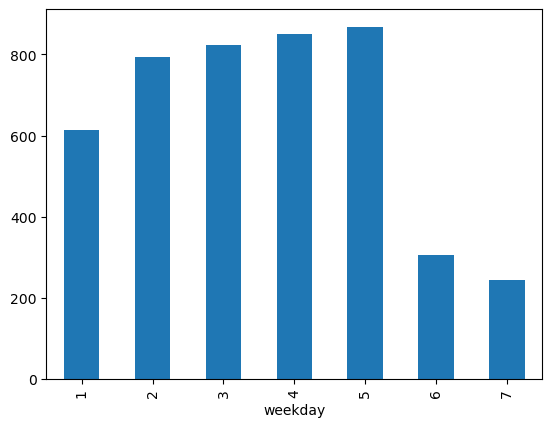

In [43]:
# please slice data for the hour 9
by_time.loc[:,8].plot(kind="bar")


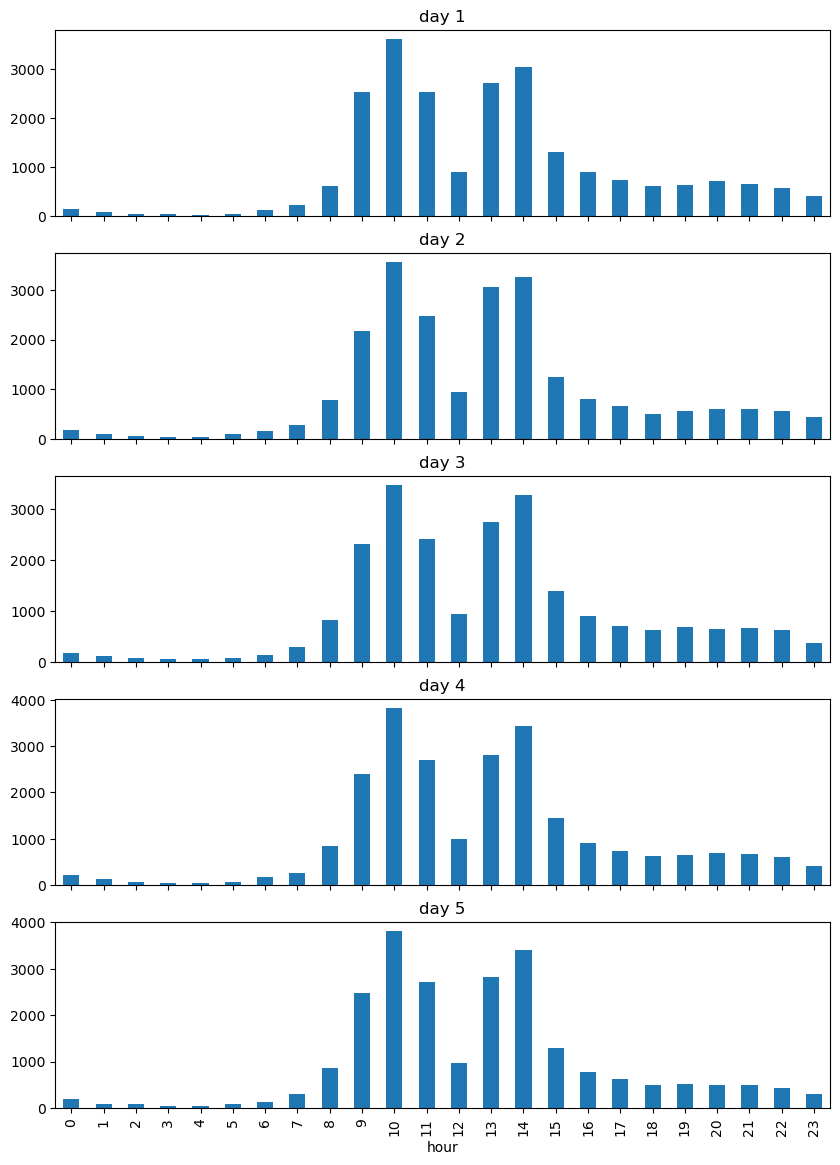

In [21]:
# plot the data for the hour 9 use bar chart
fig, ax = plt.subplots(5, 1, figsize=(10, 14),sharex=True) # 7行1列子图
for i in range(5):
    by_time.loc[i+1].plot(ax=ax[i],kind="bar",title="day {}".format(i+1))

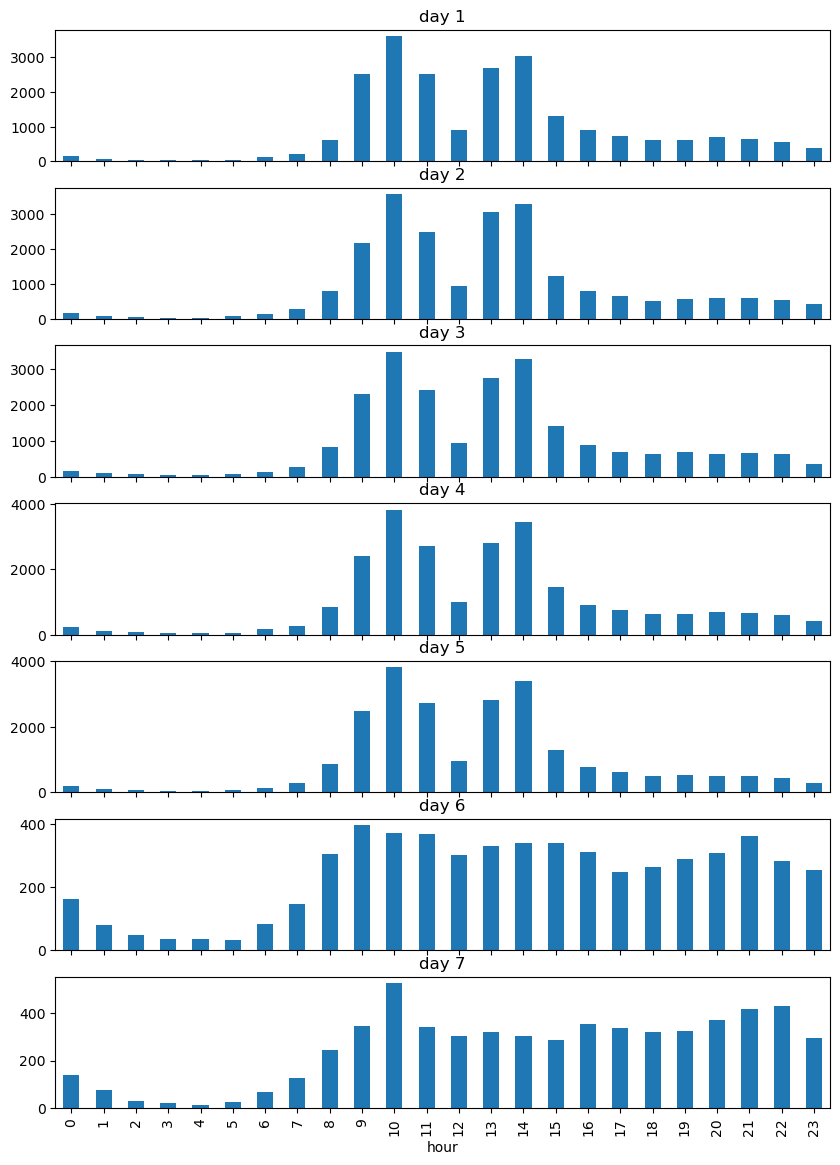

In [22]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(7, 1, figsize=(10, 14),sharex=True) # 7行1列子图
for i in range(7):
    by_time.loc[i+1].plot(ax=ax[i],kind="bar",title="day {}".format(i+1))

# homework

invite some students to share their solutiions

## review of our soulution

In [60]:
import tushare as ts
token = 'aa6d7dba75bcd6eccd5bbda27e0cf6cf56c4759ec767990bdb041575'
ts.set_token(token)
pro = ts.pro_api()

start_date='20110101'
end_date='20231231'
ts_code = '000001.SH'

df = pro.index_monthly(ts_code=ts_code, 
                              start_date=start_date, 
                              end_date=end_date, 
                              fields='ts_code,trade_date,open,high,low,close,vol,amount,change,pct_chg')

In [61]:
import pandas as pd
df["trade_date"] = pd.to_datetime(df["trade_date"])
df.set_index("trade_date",inplace=True)
df.sort_index(inplace=True)
df

,ts_code,close,open,high,low,change,pct_chg,vol,amount
trade_date,,,,,,,,,
2011-01-31,000001.SH,2790.6940,2825.3290,2868.0050,2661.4480,-17.3830,-0.0062,1.728273e+11,2.024149e+12
2011-02-28,000001.SH,2905.0530,2795.0710,2944.4130,2760.1750,114.3590,0.0410,1.756491e+11,2.163621e+12
2011-03-31,000001.SH,2928.1110,2906.2850,3012.0440,2850.9450,23.0580,0.0079,2.941033e+11,3.697126e+12
2011-04-29,000001.SH,2911.5110,2932.4810,3067.4560,2871.0100,-16.6000,-0.0057,2.309860e+11,2.727674e+12
2011-05-31,000001.SH,2743.4720,2911.5100,2933.4600,2689.2060,-168.0390,-0.0577,1.785114e+11,2.038387e+12
...,...,...,...,...,...,...,...,...,...
2022-12-30,000001.SH,3089.2579,3187.9899,3226.0817,3031.5358,-62.0774,-0.0197,6.140332e+11,7.216983e+12
2023-01-31,000001.SH,3255.6692,3087.5130,3310.4903,3073.0540,166.4113,0.0539,4.133432e+11,5.283875e+12
2023-02-28,000001.SH,3279.6053,3262.1961,3308.8279,3223.2581,23.9361,0.0074,5.627450e+11,7.206066e+12


In [62]:
import numpy as np
close = df["close"]
logtret =  close.apply(np.log).diff()
# df["one_month_logret"] = logtret.shift(-1)
df["one_month_logret"]  = logtret

In [63]:
df

,ts_code,close,open,high,low,change,pct_chg,vol,amount,one_month_logret
trade_date,,,,,,,,,,
2011-01-31,000001.SH,2790.6940,2825.3290,2868.0050,2661.4480,-17.3830,-0.0062,1.728273e+11,2.024149e+12,NaN
2011-02-28,000001.SH,2905.0530,2795.0710,2944.4130,2760.1750,114.3590,0.0410,1.756491e+11,2.163621e+12,0.040161
2011-03-31,000001.SH,2928.1110,2906.2850,3012.0440,2850.9450,23.0580,0.0079,2.941033e+11,3.697126e+12,0.007906
2011-04-29,000001.SH,2911.5110,2932.4810,3067.4560,2871.0100,-16.6000,-0.0057,2.309860e+11,2.727674e+12,-0.005685
2011-05-31,000001.SH,2743.4720,2911.5100,2933.4600,2689.2060,-168.0390,-0.0577,1.785114e+11,2.038387e+12,-0.059448
...,...,...,...,...,...,...,...,...,...,...
2022-12-30,000001.SH,3089.2579,3187.9899,3226.0817,3031.5358,-62.0774,-0.0197,6.140332e+11,7.216983e+12,-0.019895
2023-01-31,000001.SH,3255.6692,3087.5130,3310.4903,3073.0540,166.4113,0.0539,4.133432e+11,5.283875e+12,0.052467
2023-02-28,000001.SH,3279.6053,3262.1961,3308.8279,3223.2581,23.9361,0.0074,5.627450e+11,7.206066e+12,0.007325


In [64]:
by_month = df.groupby(df.index.month).mean()
by_month["one_month_logret"]

trade_date
1    -0.013071
2     0.016448
3    -0.000722
4     0.008235
5     0.003644
6    -0.016942
7    -0.009437
8    -0.009147
9    -0.008995
10    0.005973
11    0.016439
12    0.020134
Name: one_month_logret, dtype: float64

<AxesSubplot:xlabel='trade_date'>

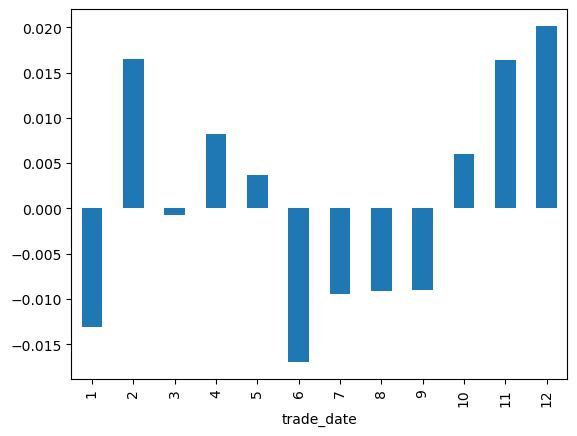

In [65]:
by_month["one_month_logret"].plot(kind="bar")

## reserach of January effect
The January effect is a hypothesis that there is a seasonal anomaly in the financial market where securities' prices increase in the month of January more than in any other month. This calendar effect would create an opportunity for investors to buy stocks for lower prices before January and sell them after their value increases. As with all calendar effects, if true, it would suggest that the market is not efficient,

这种现象最常见的理论解释：
- 对于以收入税为敏感因素并且持有小股票的个人投资者，在年底出售股票可以享受资本损失抵扣等税收优惠，之后再重新投资股票。
- 另一个原因是一月份的年终奖金支付。这些奖金中的一部分用于购买股票，推高了股价。[January_effect](https://en.wikipedia.org/wiki/January_effect)

test the  Monthly Seasonality in UK 

paper: Are Monthly Seasonals Real? A Three Century Perspective

P.1763

## do you think month is an effective factor for your investment decision

- check it for three-month or six-month log-return
- use different dataset to check your finding
- can you explain your findings
- 不同行业指数的月度平均收益率有差异吗？哪些行业不符合这个规律呢？

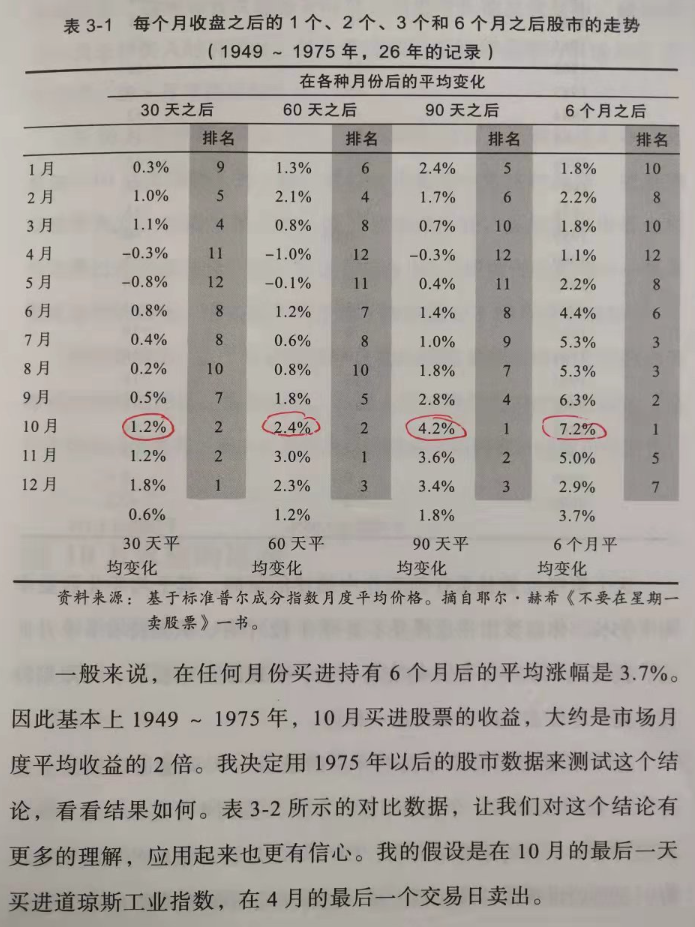

In [66]:
pro = ts.pro_api()
df = pro.index_basic(market='SSE')
df.head()

,ts_code,name,market,publisher,category,base_date,base_point,list_date
0,000001.SH,上证指数,SSE,中证公司,综合指数,19901219,100.00,19910715
1,000002.SH,上证A指,SSE,中证公司,综合指数,19901219,100.00,19920221
2,000003.SH,上证B指,SSE,中证公司,综合指数,19920221,100.00,19920221
3,000004.SH,上证工业类指数,SSE,中证公司,综合指数,19930430,1358.78,19930503
4,000005.SH,上证商业类指数,SSE,中证公司,综合指数,19930430,1358.78,19930503


请大家探索（行业：ts_code)：
- 180基建：000025.SH	
- 上证民企:000049.SH	
- 上证能源：000032.SH	
- 超大盘：000043.SH	
- 上证小盘：000045.SH	
- 上证房地产指数：000006.SH
- 上证消费：000036.SH	
- 医药等权:000075.SH
- 工业等权：000072.SH

In [67]:
def explore_period(ts_code):
    # 获取数据
    df = pro.index_monthly(ts_code=ts_code, 
                                  start_date=start_date, 
                                  end_date=end_date, 
                                  fields='ts_code,trade_date,open,high,low,close,vol,amount,change,pct_chg')
    df.trade_date = pd.DatetimeIndex(df.trade_date)
    df.set_index("trade_date",inplace=True)
    df.sort_index(inplace=True)
    
    # 计算收益率
    close = df["close"]
    df["one_month_logret"] = close.apply(np.log).diff()
    df["three_month_logret"] = close.apply(np.log) - close.shift(3).apply(np.log)
    df["six_month_logret"] = close.apply(np.log) - close.shift(6).apply(np.log)
    
    # 分组
    by_month = df.groupby(df.index.month).mean()
    cols = ["one_month_logret","three_month_logret","six_month_logret"]
    return by_month[cols]

<AxesSubplot:xlabel='trade_date'>

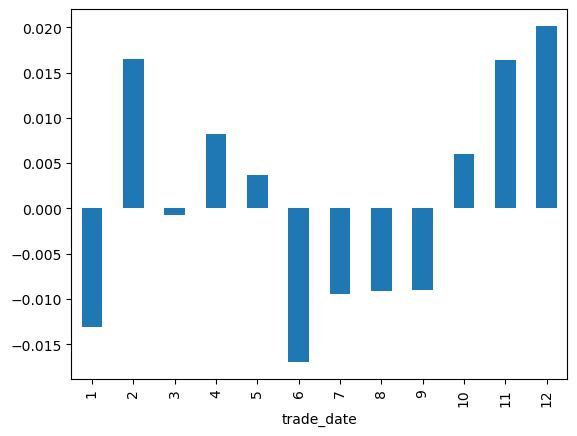

In [68]:
ts_code = "000001.SH"
r = explore_period(ts_code=ts_code)
# r.plot(kind="bar")
r["one_month_logret"].plot(kind="bar")

<AxesSubplot:xlabel='trade_date'>

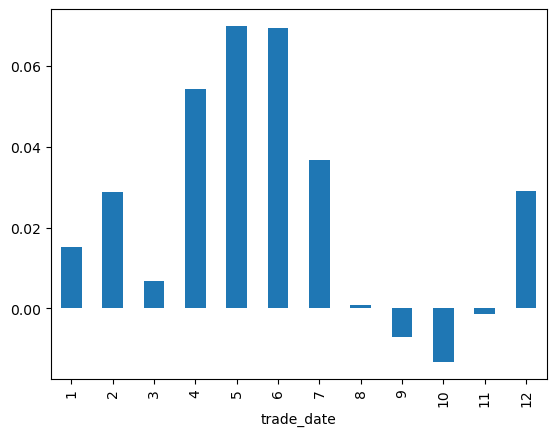

In [71]:
# 上证消费
ts_code = "000036.SH"
r = explore_period(ts_code=ts_code)
#r.plot(kind="bar", title = "consumption")
r["three_month_logret"].plot(kind="bar")

<AxesSubplot:title={'center':'Real estate'}, xlabel='trade_date'>

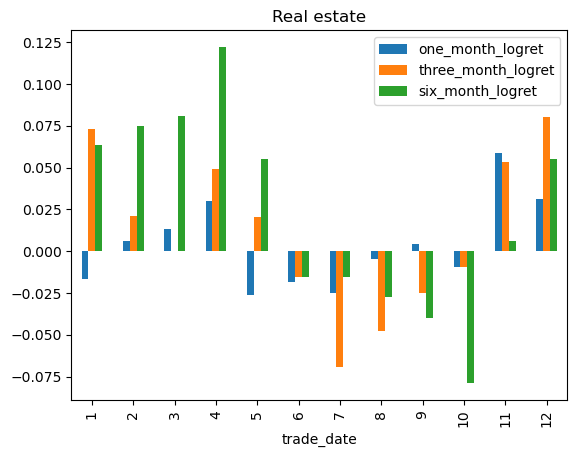

In [72]:
ts_code = "000006.SH"
r = explore_period(ts_code=ts_code)
r.plot(kind="bar", title = "Real estate")
# r["one_month_logret"].plot(kind="bar")

<AxesSubplot:title={'center':'180 infrastructure construction'}, xlabel='trade_date'>

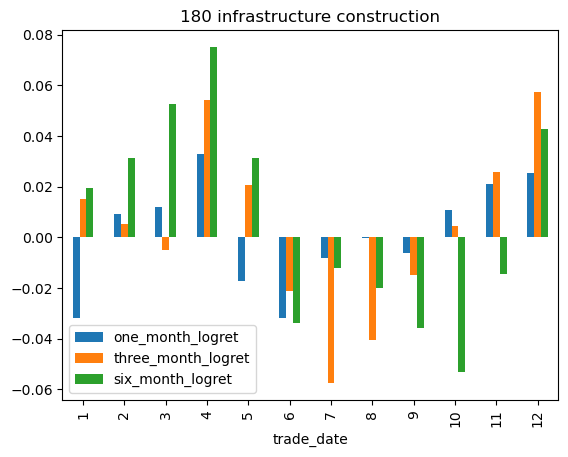

In [73]:
ts_code = "000025.SH"
r = explore_period(ts_code=ts_code)
r.plot(kind="bar",title = "180 infrastructure construction")
# r["one_month_logret"].plot(kind="bar")

# quantitative trading

关注量化交易的原因：
- 算法交易通过加快价格发现提高信息效率。对于市值较小、流动性较低且容易被忽略的公司，统计套利者（也称为配对交易）是主要的市场流动性提供者，这样可以帮助市场参与者发现有效的市场价格。  例如：两个基本面相似的公司（A和B），股票A被指数收录，由于指数基金会购买A，因此供求关系导致A公司的价格比B公司高。可以卖出股票A，买入股票B。
- 量化交易有助于推动我们深入思考，这是一个解决问题的系统化方法。例如：如何在统计套利交易中，如何判定两种金融产品的相似性，以及何种因素驱使价格背离。
- 人们具有推理、创造、从历史经验中学习的能力，因此在计划的筹备阶段，人们都有长项。但是在计划的执行阶段，常常缺乏纪律性。“亏损时要及时止损，盈利时要让利润奔跑”，但是人工执行交易时，很难完全做到。

<img src="../img/量化交易黑箱.png" align='left' height="300" width="400"/>

阿尔法代表的最普遍的意思是超额回报。

如果基金经理的工作只是购买一个指数ETF的话，那么他显然是不合格的。投资者被钱交给基金经理的唯一原因，是经理可以给予投资者比市场更好的回报。而这个更好的回报，我们就把它称之为超额回报，简称阿尔法(α)。

阿尔法模型代表乐观指数，考虑交易的金融产品的未来趋势。
- 理论驱动型 - 例如趋势跟随策略（趋势变动或者博傻理论解释）
- 数据驱动型

同时还要考虑：
- 风险，例如要控制必要的交易规模
- 成本，例如交易佣金、滑点、市场冲击成本

从现有投资组合到新的目标投资组合的交易过程：也称为再平衡。这里的频次称为再平衡周期。

<img src="../img/交易过程.png" align='left' height="500" width="700"/>

量化交易策略研究的步骤
* 获取并分析数据，并构建交易策略。这一步是非常重要，涉及数据和模型。关于模型，我们重点关注阿尔法模型（关注金融产品的未来趋势）。
* 策略回测：设置策略回测起始日期（历史数据）、初始资金、回测频率（天、分钟）
* 策略分析：策略回测报告，包括收益概况、交易明细、历史持仓、日志输出、风险指标评价、归因分析报告
* 模拟交易
* 实盘交易

这是一个循环、迭代的过程，并非是线性的。

什么是交易策略？

量化策略是以数据分析为基础，在没有人工干预的情况下的，金融产品多头、空头、中立头寸的金融交易策略。

对我们而言，算法交易策略，是由python代码表述，根据新数据决定在合适的时机买入或卖出某个或某些合适的金融资产，建立多头、空头或者中立头寸。

我们进行金融数据分析，特别是量化交易编程，对于我们的思维逻辑训练是非常有用的
- 你不能简单地告诉计算机“请帮我发现廉价的股票”。 你要用程序打开这个黑箱：从什么数据发现，如何代表廉价，股票池是什么？
- 你不能简单地告诉计算机“请帮我在合适的时间买卖这些股票”。你要编程导入行情等数据，度量合适的指标，预测牛熊转换，选择何时时间点，然后下单交易

<img src="../img/阿尔法模型.png" align='left' height="300" width="400"/>





图书《打开量化投资的黑箱》

## Seasonal ETF Investment Strategy - using seasonality

## Seasonal Investment Strategy

- 我们初步拟定在2、4、11、12月份满仓，其他月份空仓（当然，也可以做国债逆回购等其他投资操作)。
- 这里我们假设ETF能精确跟踪指数
- 先不考虑交易成本:每年只交易4次

In [98]:
import tushare as ts
import pandas as pd
token = 'aa6d7dba75bcd6eccd5bbda27e0cf6cf56c4759ec767990bdb041575'
ts.set_token(token)
pro = ts.pro_api()

start_date='20160101'
end_date='20230428'

index_daily = pro.index_daily(ts_code='000001.SH', start_date=start_date, end_date=end_date)
index_daily.trade_date = pd.DatetimeIndex(index_daily.trade_date)
index_daily.set_index("trade_date",inplace=True)
index_daily.sort_index(inplace=True)

In [99]:
index_daily

,ts_code,close,open,high,low,pre_close,change,pct_chg,vol,amount
trade_date,,,,,,,,,,
2016-01-04,000001.SH,3296.2580,3536.5890,3538.6890,3295.7410,3539.1820,-242.9240,-6.8638,184418423.0,2.409292e+08
2016-01-05,000001.SH,3287.7110,3196.6510,3328.1390,3189.6050,3296.2580,-8.5470,-0.2593,266882083.0,3.284172e+08
2016-01-06,000001.SH,3361.8400,3291.1950,3362.9740,3288.9330,3287.7110,74.1290,2.2547,238886670.0,2.852432e+08
2016-01-07,000001.SH,3125.0020,3309.6570,3309.6570,3115.8850,3361.8400,-236.8380,-7.0449,70569123.0,7.998199e+07
2016-01-08,000001.SH,3186.4120,3194.6250,3235.4510,3056.8780,3125.0020,61.4100,1.9651,286440822.0,3.241671e+08
...,...,...,...,...,...,...,...,...,...,...
2023-04-24,000001.SH,3275.4130,3300.8125,3303.0908,3264.9349,3301.2575,-25.8445,-0.7829,354255626.0,4.732660e+08
2023-04-25,000001.SH,3264.8717,3276.4030,3288.5685,3229.4461,3275.4130,-10.5413,-0.3218,380895729.0,4.942401e+08
2023-04-26,000001.SH,3264.1006,3255.2171,3277.9797,3239.9893,3264.8717,-0.7711,-0.0236,357917842.0,4.804181e+08


In [100]:
import numpy as np
index_daily["return"] = index_daily["close"].apply(np.log).diff()

In [101]:
index_daily

,ts_code,close,open,high,low,pre_close,change,pct_chg,vol,amount,return
trade_date,,,,,,,,,,,
2016-01-04,000001.SH,3296.2580,3536.5890,3538.6890,3295.7410,3539.1820,-242.9240,-6.8638,184418423.0,2.409292e+08,NaN
2016-01-05,000001.SH,3287.7110,3196.6510,3328.1390,3189.6050,3296.2580,-8.5470,-0.2593,266882083.0,3.284172e+08,-0.002596
2016-01-06,000001.SH,3361.8400,3291.1950,3362.9740,3288.9330,3287.7110,74.1290,2.2547,238886670.0,2.852432e+08,0.022297
2016-01-07,000001.SH,3125.0020,3309.6570,3309.6570,3115.8850,3361.8400,-236.8380,-7.0449,70569123.0,7.998199e+07,-0.073054
2016-01-08,000001.SH,3186.4120,3194.6250,3235.4510,3056.8780,3125.0020,61.4100,1.9651,286440822.0,3.241671e+08,0.019461
...,...,...,...,...,...,...,...,...,...,...,...
2023-04-24,000001.SH,3275.4130,3300.8125,3303.0908,3264.9349,3301.2575,-25.8445,-0.7829,354255626.0,4.732660e+08,-0.007859
2023-04-25,000001.SH,3264.8717,3276.4030,3288.5685,3229.4461,3275.4130,-10.5413,-0.3218,380895729.0,4.942401e+08,-0.003224
2023-04-26,000001.SH,3264.1006,3255.2171,3277.9797,3239.9893,3264.8717,-0.7711,-0.0236,357917842.0,4.804181e+08,-0.000236


In [102]:
# 请动手编程设计4阶段的季节投资策略
# 收益率保持在列seasonal_strategy_4stage_return中

index_daily["month"] = index_daily.index.month

# [2,3,4,11,12]
hold_month = [2,4,11,12]
def position_genrate(month):
    """
    该函数直接生成了每天的仓位，我们做其他策略时，建议分两步，首先生成交易信号，然后根据信号生成仓位
    """
    if month in set(hold_month):
        return 1
    else:
        return 0

# apply a function to a column to create a new variable
index_daily["position_4stage"] = index_daily.month.apply(position_genrate)

index_daily["seasonal_strategy_4stage_return"] = index_daily["position_4stage"] * index_daily["return"]

In [108]:
index_daily.columns

Index(['ts_code', 'close', 'open', 'high', 'low', 'pre_close', 'change',
       'pct_chg', 'vol', 'amount', 'return', 'month', 'position_4stage',
       'seasonal_strategy_4stage_return', 'bond_return', 'season_bond_return'],
      dtype='object')

<AxesSubplot:xlabel='trade_date'>

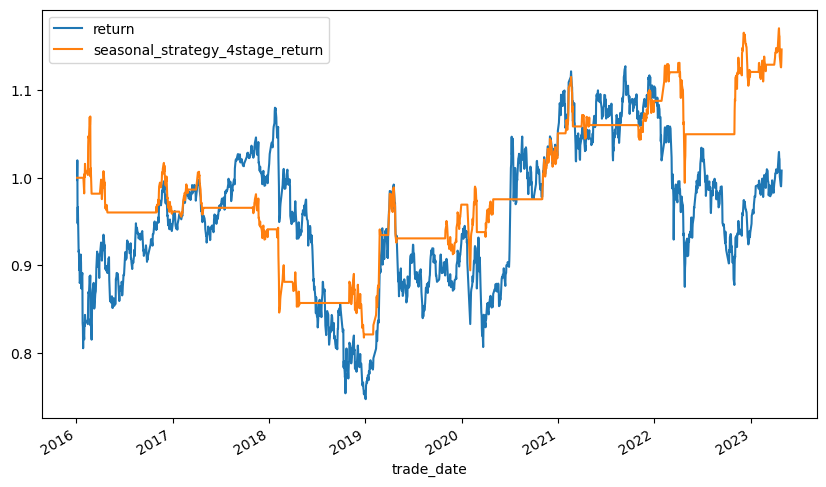

In [103]:
# 计算累计的资金图
index_daily[["return","seasonal_strategy_4stage_return",""]].cumsum().apply(np.exp).plot(figsize=(10,6))

## hold money fund or National debt reverse repurchase  when you do not hold ETF

In [105]:
np.log(1+0.0001)

9.999500033329732e-05

<AxesSubplot:xlabel='trade_date'>

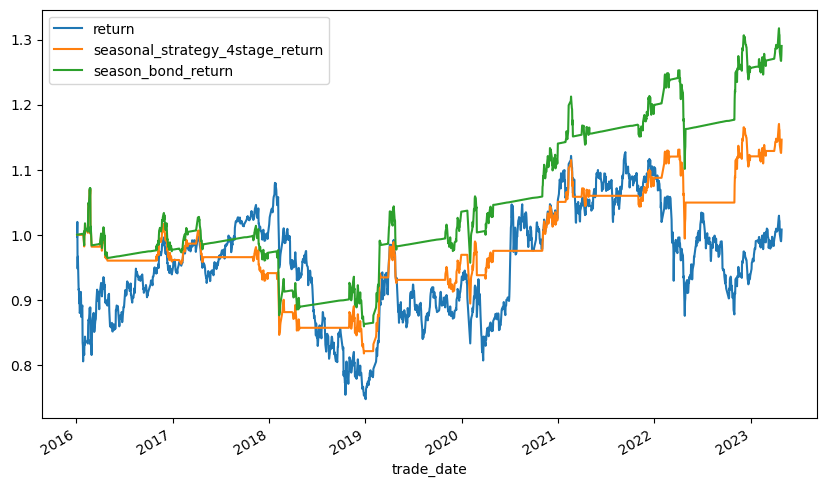

In [109]:
## 假设持有国债的收益率每日的对数收益率 = 0.0001
def bond_return_genrate(month):
    if month in set(hold_month):
        return 0.0
    else:
        return 0.0001

index_daily["bond_return"] = index_daily.month.apply(bond_return_genrate)

index_daily["season_bond_return"] = index_daily.seasonal_strategy_4stage_return + index_daily.bond_return

index_daily[["return","seasonal_strategy_4stage_return","season_bond_return"]].cumsum().apply(np.exp).plot(figsize=(10,6))




## considering the trasaction cost

$log(1+x) \approx x$ when x is very small
try: np.log(1+0.003)

In [114]:
# 生成交易成本
pos = (index_daily.seasonal_strategy_4stage_return!=0).astype(np.int0)
tran = abs(pos.diff())
index_daily["tran_cost"] = tran * 0.003

In [118]:
# 也可以考虑按月分组，取第一个交易日，然后根据月份判定是否交易
index_daily["trade_date"] = index_daily.index
first_tradedate = index_daily.groupby([index_daily.index.year,index_daily.index.month]).first()
first_tradedate.set_index("trade_date")

# join merge 

,ts_code,close,open,high,low,pre_close,change,pct_chg,vol,amount,return,month,position_4stage,seasonal_strategy_4stage_return,bond_return,season_bond_return,tran_cost,season_bond_cost_return
trade_date,,,,,,,,,,,,,,,,,,
2016-01-04,000001.SH,3296.2580,3536.5890,3538.6890,3295.7410,3539.1820,-242.9240,-6.8638,184418423.0,2.409292e+08,-0.002596,1,0,-0.000000,0.0001,0.000100,0.003,-0.002900
2016-02-01,000001.SH,2688.8540,2730.9840,2735.2550,2655.6230,2737.6000,-48.7460,-1.7806,156383744.0,1.528307e+08,-0.017967,2,1,-0.017967,0.0000,-0.017967,0.003,-0.020967
2016-03-01,000001.SH,2733.1700,2688.3800,2747.5620,2668.7570,2687.9790,45.1910,1.6812,187207443.0,1.821855e+08,0.016672,3,0,0.000000,0.0001,0.000100,0.003,-0.002900
2016-04-01,000001.SH,3009.5300,2997.0880,3009.6730,2956.2470,3003.9150,5.6150,0.1869,206545866.0,2.175205e+08,0.001867,4,1,0.001867,0.0000,0.001867,0.003,-0.001133
2016-05-03,000001.SH,2992.6430,2940.3920,2993.5350,2929.8150,2938.3240,54.3190,1.8486,168703643.0,1.958166e+08,0.018318,5,0,0.000000,0.0001,0.000100,0.003,-0.002900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-01,000001.SH,3165.4711,3187.9899,3198.4088,3164.5348,3151.3353,14.1358,0.4486,387013056.0,4.621850e+08,0.004476,12,1,0.004476,0.0000,0.004476,0.000,0.004476
2023-01-03,000001.SH,3116.5119,3087.5130,3119.8556,3073.0540,3089.2579,27.2540,0.8822,281370362.0,3.313921e+08,0.008783,1,0,0.000000,0.0001,0.000100,0.003,-0.002900
2023-02-01,000001.SH,3284.9213,3262.1961,3284.9224,3245.4113,3255.6692,29.2521,0.8985,339509410.0,4.133952e+08,0.008945,2,1,0.008945,0.0000,0.008945,0.003,0.005945


In [115]:
index_daily["season_bond_cost_return"] = index_daily["seasonal_strategy_4stage_return"] + index_daily["bond_return"] - index_daily["tran_cost"]

In [116]:
index_daily

,ts_code,close,open,high,low,pre_close,change,pct_chg,vol,amount,return,month,position_4stage,seasonal_strategy_4stage_return,bond_return,season_bond_return,tran_cost,season_bond_cost_return
trade_date,,,,,,,,,,,,,,,,,,
2016-01-04,000001.SH,3296.2580,3536.5890,3538.6890,3295.7410,3539.1820,-242.9240,-6.8638,184418423.0,2.409292e+08,NaN,1,0,NaN,0.0001,NaN,NaN,NaN
2016-01-05,000001.SH,3287.7110,3196.6510,3328.1390,3189.6050,3296.2580,-8.5470,-0.2593,266882083.0,3.284172e+08,-0.002596,1,0,-0.000000,0.0001,0.000100,0.003,-0.002900
2016-01-06,000001.SH,3361.8400,3291.1950,3362.9740,3288.9330,3287.7110,74.1290,2.2547,238886670.0,2.852432e+08,0.022297,1,0,0.000000,0.0001,0.000100,0.000,0.000100
2016-01-07,000001.SH,3125.0020,3309.6570,3309.6570,3115.8850,3361.8400,-236.8380,-7.0449,70569123.0,7.998199e+07,-0.073054,1,0,-0.000000,0.0001,0.000100,0.000,0.000100
2016-01-08,000001.SH,3186.4120,3194.6250,3235.4510,3056.8780,3125.0020,61.4100,1.9651,286440822.0,3.241671e+08,0.019461,1,0,0.000000,0.0001,0.000100,0.000,0.000100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-04-24,000001.SH,3275.4130,3300.8125,3303.0908,3264.9349,3301.2575,-25.8445,-0.7829,354255626.0,4.732660e+08,-0.007859,4,1,-0.007859,0.0000,-0.007859,0.000,-0.007859
2023-04-25,000001.SH,3264.8717,3276.4030,3288.5685,3229.4461,3275.4130,-10.5413,-0.3218,380895729.0,4.942401e+08,-0.003224,4,1,-0.003224,0.0000,-0.003224,0.000,-0.003224
2023-04-26,000001.SH,3264.1006,3255.2171,3277.9797,3239.9893,3264.8717,-0.7711,-0.0236,357917842.0,4.804181e+08,-0.000236,4,1,-0.000236,0.0000,-0.000236,0.000,-0.000236


<AxesSubplot:xlabel='trade_date'>

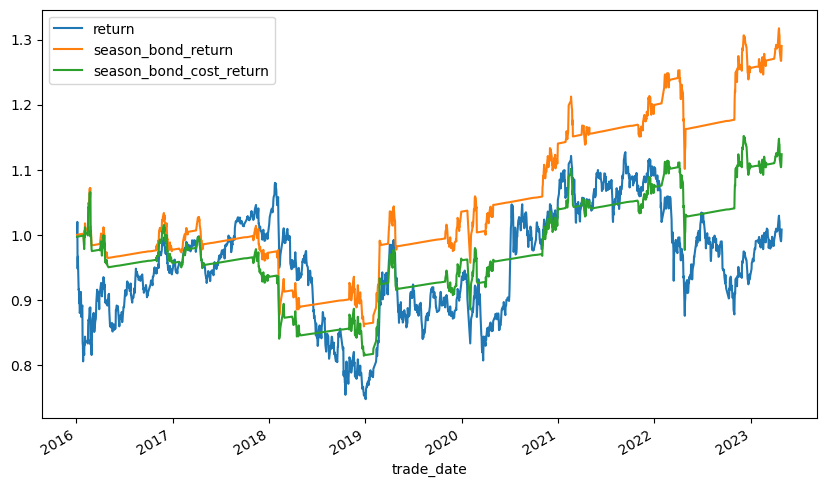

In [117]:
index_daily[["return","season_bond_return","season_bond_cost_return"]].cumsum().apply(np.exp).plot(figsize=(10,6))

## discussion
- do you think the investment strategy is good?
- how to evaluate it further?
- do you think the months we select is the best?

# technical indicators

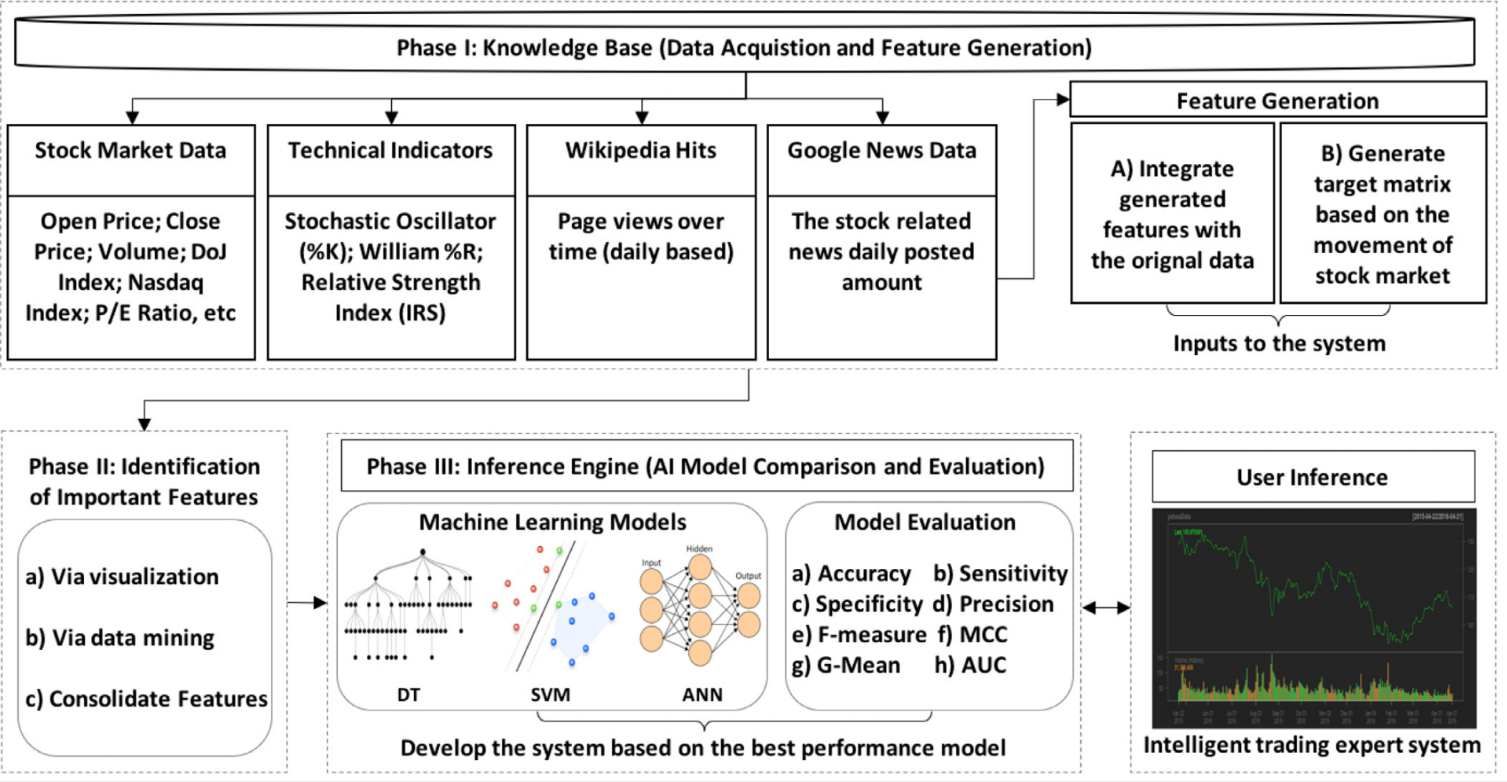

# learnging in group after class

常用的股票投资技术指标有很多，以下是其中一些常见的指标：

- 移动平均线（Moving Average，MA）
- 相对强弱指数（Relative Strength Index，RSI）
- 移动平均线收敛/发散指标（Moving Average Convergence Divergence，MACD）
- 布林带（Bollinger Bands）

要求：
- 指标的含义
- 指标的计算公式
- 如何根据技术指标做投资策略
- 下周随机邀请四位同学分享（2个同学1个小组）
- 在2011年之前的数据开发回测，在2011年开始的数据上进一步模拟交易
- data 参考如下

In [119]:
import tushare as ts
import pandas as pd
token = 'aa6d7dba75bcd6eccd5bbda27e0cf6cf56c4759ec767990bdb041575'
ts.set_token(token)
pro = ts.pro_api()

start_date='20010101'
end_date='20230505'

index_daily = pro.index_daily(ts_code='000001.SH', start_date=start_date, end_date=end_date)
index_daily.trade_date = pd.DatetimeIndex(index_daily.trade_date)
index_daily.set_index("trade_date",inplace=True)
index_daily.sort_index(inplace=True)

In [120]:
index_daily

,ts_code,close,open,high,low,pre_close,change,pct_chg,vol,amount
trade_date,,,,,,,,,,
2001-01-02,000001.SH,2103.4690,2077.0760,2103.5380,2074.8820,2073.4770,29.9920,1.4465,18650746.0,1.340509e+07
2001-01-03,000001.SH,2123.8990,2108.2540,2123.9000,2105.4970,2103.4690,20.4300,0.9713,17157673.0,1.751683e+07
2001-01-04,000001.SH,2117.4050,2125.4850,2127.4190,2113.1790,2123.8990,-6.4940,-0.3058,13423541.0,1.429525e+07
2001-01-05,000001.SH,2125.3000,2117.6640,2125.3810,2114.0560,2117.4050,7.8950,0.3729,13288175.0,1.484424e+07
2001-01-08,000001.SH,2102.0640,2128.6020,2131.9800,2092.0970,2125.3000,-23.2360,-1.0933,14787085.0,1.588766e+07
...,...,...,...,...,...,...,...,...,...,...
2023-04-25,000001.SH,3264.8717,3276.4030,3288.5685,3229.4461,3275.4130,-10.5413,-0.3218,380895729.0,4.942401e+08
2023-04-26,000001.SH,3264.1006,3255.2171,3277.9797,3239.9893,3264.8717,-0.7711,-0.0236,357917842.0,4.804181e+08
2023-04-27,000001.SH,3285.8844,3256.2278,3299.3010,3253.1117,3264.1006,21.7838,0.6674,341590534.0,4.661754e+08
